Import Libraries

In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

Check working directory

In [4]:
import os

print(os.getcwd())

d:\Study\2nd sem1\ML practicles\experiments


Load the dataset 


In [6]:
df = pd.read_csv("../datasets/house_price_dataset.csv")

print(df.head())
print(df.shape)

   House_ID  Area_sqft  Bedrooms  Bathrooms  Floors  Year_Built     Location  \
0      3975     1665.3       2.0        4.0     1.0        1988  Green field   
1     12325     2646.2       2.0        5.0     2.0        2005    riverside   
2      7202     2791.2       4.0        3.0     3.0        2011    Lake side   
3      8355     1594.1       2.0        3.0     1.0        1972     Hillview   
4     12742     3227.0       3.0        5.0     2.0        1995          NaN   

  Furnishing_Status Parking_Available  Garage_Count  Lot_Size_sqft  Condition  \
0       Unfurnished                NO           3.0         4817.2  Excellent   
1               NaN                no           3.0         6998.6  EXCELLENT   
2       Unfurnished                NO           0.0         3427.6       good   
3     semifurnished                no           3.0         5703.1       fair   
4       Unfurnished               yes           3.0         7352.4       Good   

   Distance_to_City_Center_km  C

Select the required columns

In [3]:
df = df[['Area_sqft', 'Price']]

print(df.head())


   Area_sqft     Price
0     1665.3  309277.0
1     2646.2  563512.0
2     2791.2  495806.0
3     1594.1  240776.0
4     3227.0  413975.0


Handle missing values

In [4]:
df = df.dropna()

print(df.isnull().sum())

Area_sqft    0
Price        0
dtype: int64


Separate X and Y

In [5]:
X = df[['Area_sqft']]

y = df['Price']

Split the dataset

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Train the model

In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

LinearRegression()

Make predictions

In [8]:
y_pred = model.predict(X_test)

print("Predicted Prices:")
print(y_pred[:5])

Predicted Prices:
[334706.13924202 379141.43566443 462908.77816143 461626.35514656
 597100.46476883]


Evaluate the model

In [9]:
print("Slope:", model.coef_)

print("Intercept:", model.intercept_)

print("Mean Squared Error:",
      mean_squared_error(y_test, y_pred))

print("R2 Score:",
      r2_score(y_test, y_pred))

Slope: [132.20855823]
Intercept: 79530.40099478682
Mean Squared Error: 5322114033.143034
R2 Score: 0.6697787203119367


Visualize the regression line

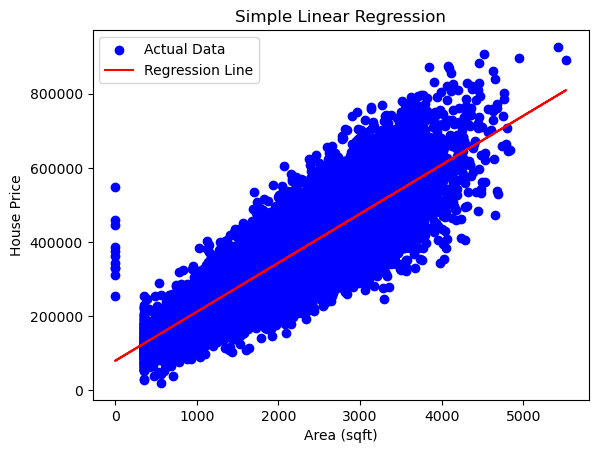

In [10]:
plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(X, model.predict(X),
         color='red', label='Regression Line')

plt.xlabel("Area (sqft)")
plt.ylabel("House Price")

plt.title("Simple Linear Regression")

plt.legend()
plt.show()